# Diamond Price Prediction & Market Analysis
### Data Science Mini Project

---

## 1. Project Overview & Problem Statement
The diamond market is multi-billion dollar luxury industry where valuation has historically relied on the **4 Cs**: **Carat**, **Cut**, **Color**, and **Clarity**, alongside physical dimension metrics ($x$, $y$, $z$, depth, table).

### Project Objectives:
1. **Data Cleaning & Anomaly Detection**: Identify and remove physically impossible values (e.g., zero dimensions) and extreme outliers.
2. **Exploratory Data Analysis (EDA)**: Understand univariate and bivariate distributions, and rigorously investigate counter-intuitive market anomalies (e.g., Simpson's Paradox in Color/Clarity vs. Price).
3. **Feature Engineering**: Derive domain-specific indicators such as diamond physical volume ($x \times y \times z$) and encode ordinal categorical features.
4. **Predictive Modeling**: Train and compare multiple regression models:
   - **Baseline**: Multiple Linear Regression
   - **Non-Linear Tree**: Decision Tree Regressor
   - **Ensemble Bagging**: Random Forest Regressor
5. **Rigorous Evaluation**: Benchmark performance using $R^2$, Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE), and analyze feature importance.


In [9]:
# Import core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

warnings.filterwarnings('ignore')

# Set visual aesthetic standards
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Data Loading & Initial Inspection
We load the dataset `diamonds.csv` and inspect its shape, column types, and basic statistics.


In [10]:
from google.colab import files
uploaded = files.upload()


Saving diamonds.csv to diamonds (1).csv


In [11]:
# Load dataset
df = pd.read_csv('diamonds.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(df.head())

Dataset Shape: 50000 rows, 10 columns
   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75


In [12]:
# Check data types and presence of null values
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    50000 non-null  float64
 1   cut      50000 non-null  object 
 2   color    50000 non-null  object 
 3   clarity  50000 non-null  object 
 4   depth    50000 non-null  float64
 5   table    50000 non-null  float64
 6   price    50000 non-null  int64  
 7   x        50000 non-null  float64
 8   y        50000 non-null  float64
 9   z        50000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 3.8+ MB


In [13]:
# Statistical summary of numerical features
print(df.describe())


              carat         depth         table         price             x  \
count  50000.000000  50000.000000  50000.000000  50000.000000  50000.000000   
mean       0.799444     61.753006     57.457830   3944.805440      5.734403   
std        0.475173      1.431088      2.232092   3997.938105      1.123077   
min        0.200000     43.000000     43.000000    326.000000      0.000000   
25%        0.400000     61.000000     56.000000    951.000000      4.710000   
50%        0.700000     61.800000     57.000000   2410.000000      5.700000   
75%        1.040000     62.500000     59.000000   5351.000000      6.540000   
max        5.010000     79.000000     95.000000  18823.000000     10.740000   

                  y             z  
count  50000.000000  50000.000000  
mean       5.737956      3.541056  
std        1.145579      0.707065  
min        0.000000      0.000000  
25%        4.720000      2.910000  
50%        5.710000      3.530000  
75%        6.540000      4.040000  


## 3. Data Cleaning & Anomaly Detection
A careful inspection of the summary statistics reveals critical physical anomalies:
- Minimum values for dimensions $x$, $y$, and $z$ are `0.0 mm`. A physical 3D diamond cannot have zero length, width, or depth!
- Extreme outlier values exist in $y$ and $z$ ($> 30\text{ mm}$), which represent erroneous data entries.


In [14]:
# Check count of diamonds with impossible zero dimensions
zero_dims = df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)]
print(f"Number of diamonds with 0 in x, y, or z: {len(zero_dims)}")

# Check for extreme dimensional outliers
extreme_outliers = df[(df['y'] > 20) | (df['z'] > 20)]
print(f"Number of diamonds with extreme dimensions (y or z > 20 mm): {len(extreme_outliers)}")


Number of diamonds with 0 in x, y, or z: 17
Number of diamonds with extreme dimensions (y or z > 20 mm): 3


In [15]:
# Clean the dataset by removing zero dimensions and extreme measurement errors
initial_count = len(df)
df = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)]
df = df[(df['y'] < 20) & (df['z'] < 20)].copy()

dropped_count = initial_count - len(df)
print(f"Dropped {dropped_count} anomalous rows. Clean dataset size: {len(df)} rows.")


Dropped 20 anomalous rows. Clean dataset size: 49980 rows.


## 4. Feature Engineering & Preprocessing
To improve the predictive capacity of our models:
1. **Diamond Volume**: A diamond's price is heavily determined by its 3D size. We compute approximated volume as:
   $$\text{volume} = x \times y \times z$$
2. **Ordinal Encoding**: Cut, Color, and Clarity have intrinsic natural order based on Gemological Institute of America (GIA) grading standards:
   - **Cut**: $\text{Fair (1)} < \text{Good (2)} < \text{Very Good (3)} < \text{Premium (4)} < \text{Ideal (5)}$
   - **Color**: $\text{J (1, worst)} < \text{I (2)} < \dots < \text{D (7, best colourless)}$
   - **Clarity**: $\text{I1 (1, worst)} < \text{SI2 (2)} < \text{SI1 (3)} < \text{VS2 (4)} < \text{VS1 (5)} < \text{VVS2 (6)} < \text{VVS1 (7)} < \text{IF (8, flawless)}$


In [16]:
# Feature Engineering: Volume
df['volume'] = df['x'] * df['y'] * df['z']

# Encode categorical variables using domain-standard ordinal mappings
cut_map = {'Fair': 1, 'Good': 2, 'Very Good': 3, 'Premium': 4, 'Ideal': 5}
color_map = {'J': 1, 'I': 2, 'H': 3, 'G': 4, 'F': 5, 'E': 6, 'D': 7}
clarity_map = {'I1': 1, 'SI2': 2, 'SI1': 3, 'VS2': 4, 'VS1': 5, 'VVS2': 6, 'VVS1': 7, 'IF': 8}

df['cut'] = df['cut'].map(cut_map)
df['color'] = df['color'].map(color_map)
df['clarity'] = df['clarity'].map(clarity_map)

df[['carat', 'cut', 'color', 'clarity', 'volume', 'price']].head()
print("Engineered dataset preview:")
print(df[['carat', 'cut', 'color', 'clarity', 'volume', 'price']].head())


Engineered dataset preview:
   carat  cut  color  clarity     volume  price
0   0.23    5      6        2  38.202030    326
1   0.21    4      6        3  34.505856    326
2   0.23    2      6        5  38.076885    327
3   0.29    4      2        4  46.724580    334
4   0.31    2      1        2  51.917250    335


## 5. Exploratory Data Analysis (EDA)

### 5.1 Univariate Analysis: Distributions of Price and Carat
We examine the distribution of our target variable (`price`) and primary predictor (`carat`).


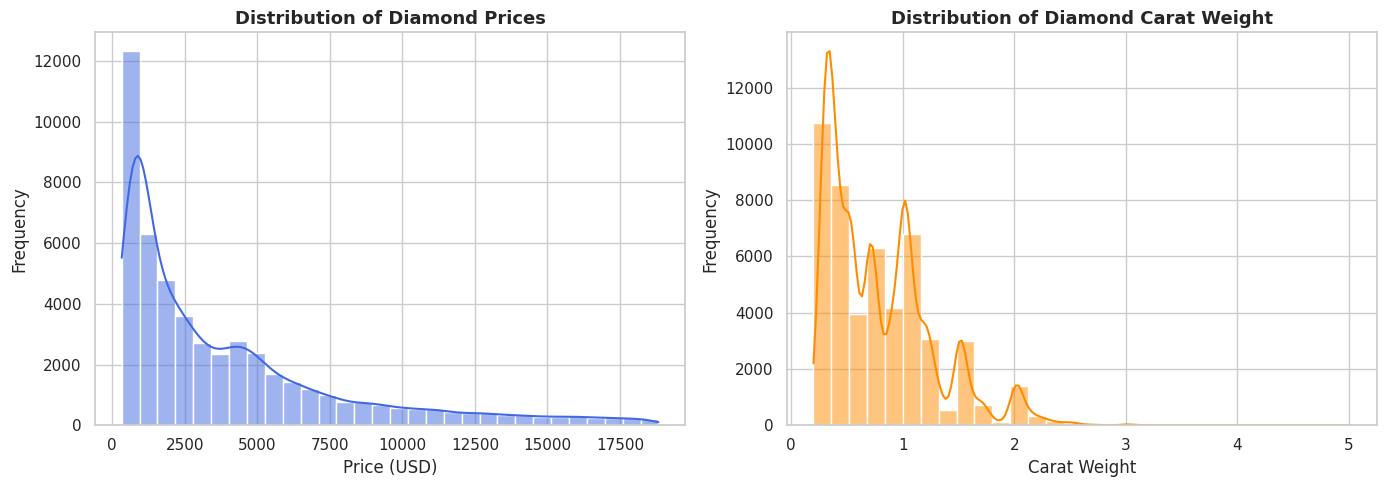

Median Price: $2,409.00 | Mean Price: $3,942.99
Median Carat: 0.70 | Mean Carat: 0.80


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Price distribution
sns.histplot(df['price'], bins=30, kde=True, color='royalblue', ax=axes[0])
axes[0].set_title('Distribution of Diamond Prices', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price (USD)')
axes[0].set_ylabel('Frequency')

# Carat distribution
sns.histplot(df['carat'], bins=30, kde=True, color='darkorange', ax=axes[1])
axes[1].set_title('Distribution of Diamond Carat Weight', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Carat Weight')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print(f"Median Price: ${df['price'].median():,.2f} | Mean Price: ${df['price'].mean():,.2f}")
print(f"Median Carat: {df['carat'].median():.2f} | Mean Carat: {df['carat'].mean():.2f}")


### 5.2 Categorical Feature Breakdown: Cut, Color, and Clarity
We inspect the distribution across the 4C quality tiers.


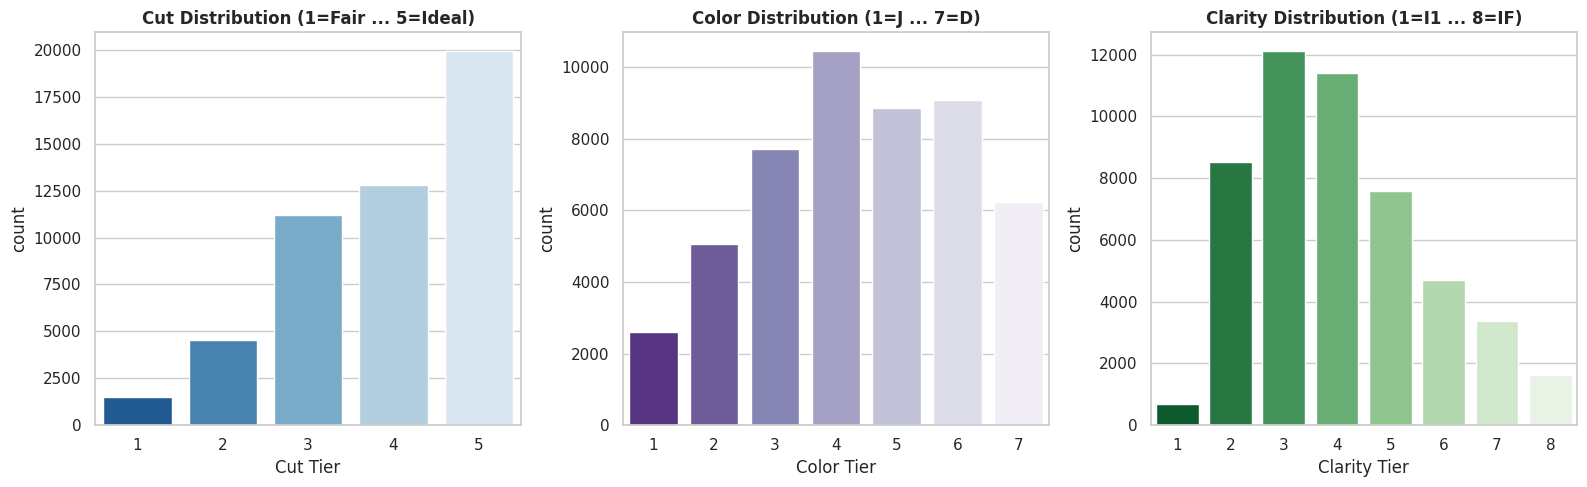

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Cut count
sns.countplot(x='cut', data=df, palette='Blues_r', ax=axes[0])
axes[0].set_title('Cut Distribution (1=Fair ... 5=Ideal)', fontweight='bold')
axes[0].set_xlabel('Cut Tier')

# Color count
sns.countplot(x='color', data=df, palette='Purples_r', ax=axes[1])
axes[1].set_title('Color Distribution (1=J ... 7=D)', fontweight='bold')
axes[1].set_xlabel('Color Tier')

# Clarity count
sns.countplot(x='clarity', data=df, palette='Greens_r', ax=axes[2])
axes[2].set_title('Clarity Distribution (1=I1 ... 8=IF)', fontweight='bold')
axes[2].set_xlabel('Clarity Tier')

plt.tight_layout()
plt.show()


### 5.3 Investigating Simpson's Paradox (The Price vs. Color/Clarity Anomaly)
When plotting average `price` against `color` or `clarity`, we observe a surprising contradiction:
- Diamonds with **inferior color (J)** and **inferior clarity (I1)** appear to have **higher average prices** than top-tier D-color and IF-clarity diamonds!
- **Why does this happen?** Let's investigate the relationship with **Carat weight** and calculate **Price per Carat**.


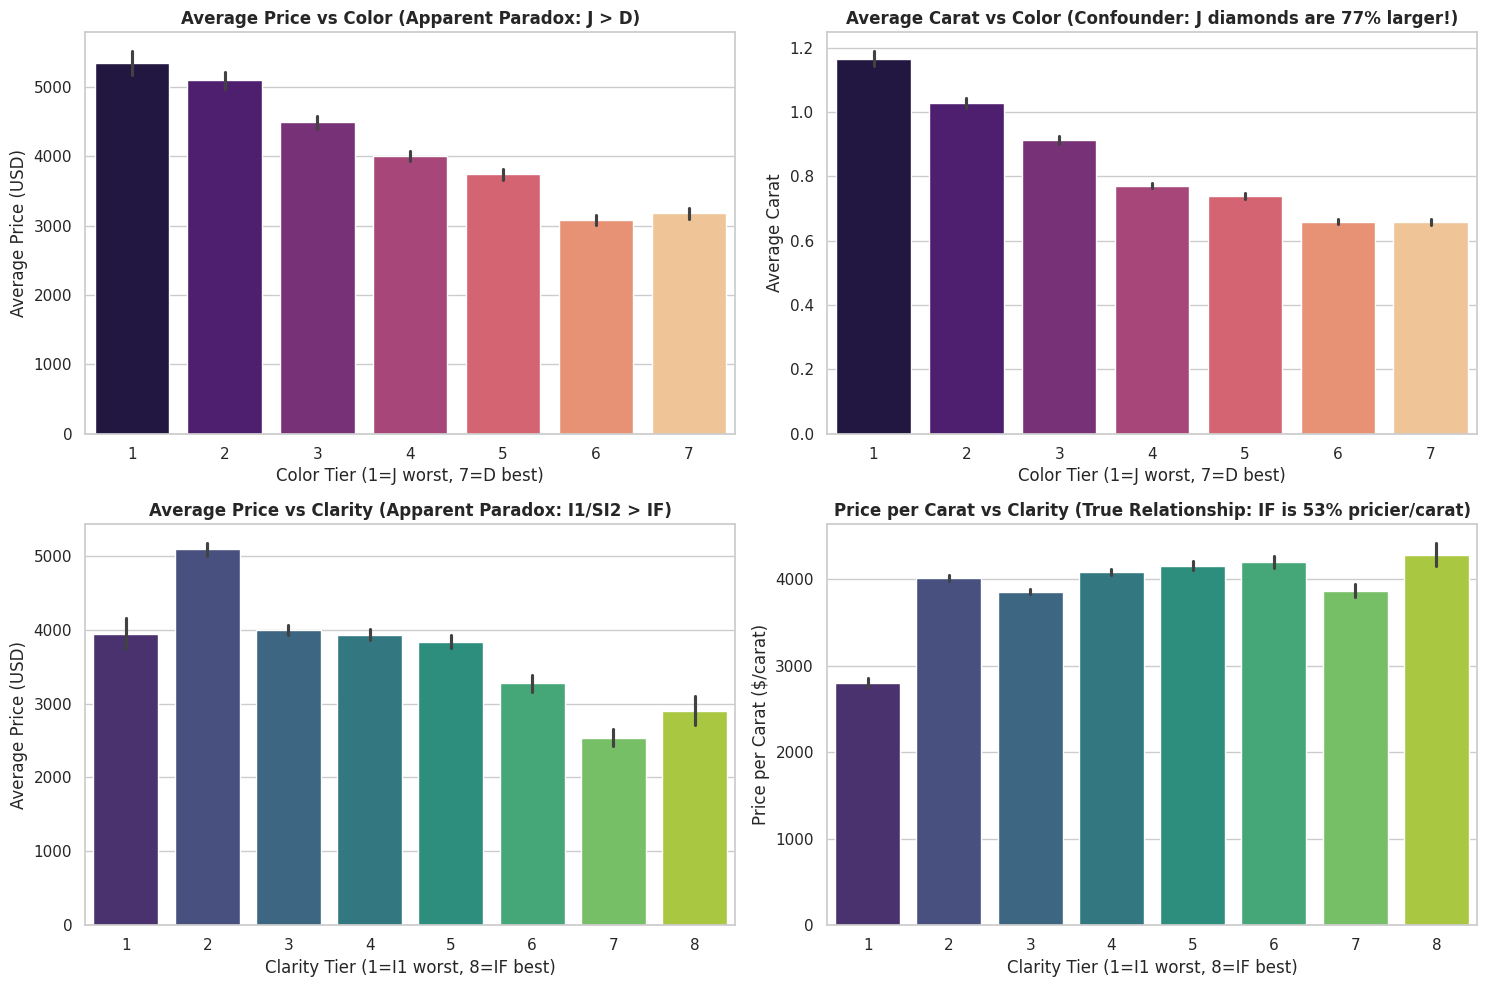

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Total Price vs Color (Apparent paradox)
sns.barplot(x='color', y='price', data=df, palette='magma', ax=axes[0, 0])
axes[0, 0].set_title('Average Price vs Color (Apparent Paradox: J > D)', fontweight='bold')
axes[0, 0].set_xlabel('Color Tier (1=J worst, 7=D best)')
axes[0, 0].set_ylabel('Average Price (USD)')

# 2. Carat Weight vs Color (Confounder revealed)
sns.barplot(x='color', y='carat', data=df, palette='magma', ax=axes[0, 1])
axes[0, 1].set_title('Average Carat vs Color (Confounder: J diamonds are 77% larger!)', fontweight='bold')
axes[0, 1].set_xlabel('Color Tier (1=J worst, 7=D best)')
axes[0, 1].set_ylabel('Average Carat')

# 3. Total Price vs Clarity (Apparent paradox)
sns.barplot(x='clarity', y='price', data=df, palette='viridis', ax=axes[1, 0])
axes[1, 0].set_title('Average Price vs Clarity (Apparent Paradox: I1/SI2 > IF)', fontweight='bold')
axes[1, 0].set_xlabel('Clarity Tier (1=I1 worst, 8=IF best)')
axes[1, 0].set_ylabel('Average Price (USD)')

# 4. Normalized: Price per Carat vs Clarity (True market relationship)
df['price_per_carat'] = df['price'] / df['carat']
sns.barplot(x='clarity', y='price_per_carat', data=df, palette='viridis', ax=axes[1, 1])
axes[1, 1].set_title('Price per Carat vs Clarity (True Relationship: IF is 53% pricier/carat)', fontweight='bold')
axes[1, 1].set_xlabel('Clarity Tier (1=I1 worst, 8=IF best)')
axes[1, 1].set_ylabel('Price per Carat ($/carat)')

# Clean up helper column
df.drop('price_per_carat', axis=1, inplace=True)

plt.tight_layout()
plt.show()


**Key Insight (Resolving the Paradox):**
Low-grade diamonds (J color or I1 clarity) are only economically mined and marketed if their **carat weight is substantially larger** (mean 1.16 carats vs 0.66 carats for D-color). When we control for size by looking at **Price per Carat**, the expected economic hierarchy holds true: Flawless (IF) diamonds command \$4,281/carat compared to only \$2,800/carat for I1 diamonds (~53% premium).


### 5.4 Carat vs. Price Non-Linearity
We plot the relationship between Carat and Price to understand functional form.


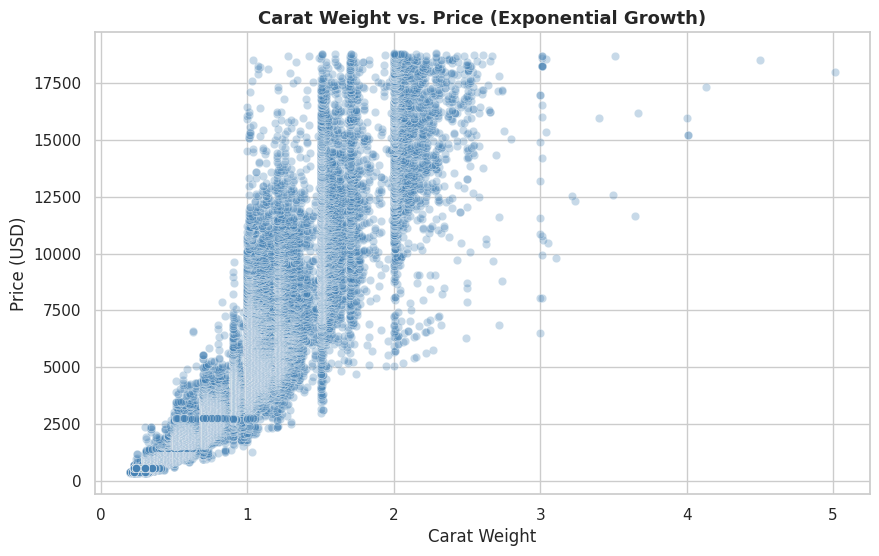

In [20]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='carat', y='price', data=df, alpha=0.3, color='steelblue')
plt.title('Carat Weight vs. Price (Exponential Growth)', fontsize=13, fontweight='bold')
plt.xlabel('Carat Weight')
plt.ylabel('Price (USD)')
plt.show()


## 6. Correlation Analysis
We generate a correlation heatmap to analyze multicollinearity and feature associations.


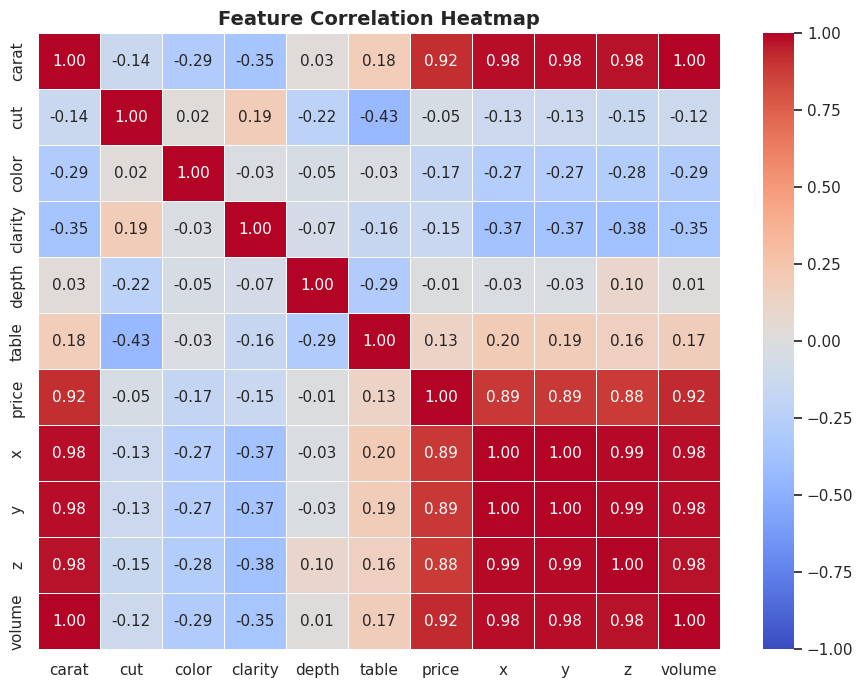

Top correlations with Price:
price      1.000000
volume     0.923763
carat      0.921808
y          0.889337
x          0.887731
z          0.882350
table      0.129982
depth     -0.012766
cut       -0.053516
clarity   -0.146878
color     -0.172537
Name: price, dtype: float64


In [21]:
plt.figure(figsize=(11, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.show()

print("Top correlations with Price:")
print(corr_matrix['price'].sort_values(ascending=False))


**Correlation Observations:**
- `carat` (0.92) and engineered `volume` (0.90) exhibit extremely high positive correlation with `price`.
- Physical dimensions `x` (0.88), `y` (0.87), and `z` (0.86) are collinear with carat.
- `depth` and `table` show weak correlation with total price.


## 7. Train-Test Split
We split the data into **80% training set** and **20% testing set** with a fixed `random_state=42` for strict reproducibility.


In [22]:
from sklearn.model_selection import train_test_split

X = df.drop('price', axis=1)
y = df['price']

# Standard train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training feature set shape: {X_train.shape} (80%)")
print(f"Testing feature set shape:  {X_test.shape} (20%)")
print(f"Training target shape:      {y_train.shape}")
print(f"Testing target shape:       {y_test.shape}")


Training feature set shape: (39984, 10) (80%)
Testing feature set shape:  (9996, 10) (20%)
Training target shape:      (39984,)
Testing target shape:       (9996,)


## 8. Model Building & Training

We benchmark three distinct algorithms:
1. **Multiple Linear Regression**: Serves as our parametric baseline to evaluate whether linear combinations capture diamond pricing.
2. **Decision Tree Regressor**: Non-linear tree-based partitioning model.
3. **Random Forest Regressor**: Ensemble bagging model that averages multiple de-correlated decision trees to minimize prediction variance and prevent overfitting.


In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Initialize candidate models
models = {
    'Linear Regression (Baseline)': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

trained_models = {}
predictions = {}
timings = {}

for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start_time

    trained_models[name] = model
    predictions[name] = {
        'train': model.predict(X_train),
        'test': model.predict(X_test)
    }
    timings[name] = elapsed
    print(f"Trained {name} in {elapsed:.2f} seconds.")


Trained Linear Regression (Baseline) in 0.03 seconds.
Trained Decision Tree Regressor in 0.49 seconds.
Trained Random Forest Regressor in 25.71 seconds.


## 9. Model Evaluation & Comparison Table
We evaluate models across three standard regression metrics:
- **$R^2$ (Coefficient of Determination)**: Proportion of variance in diamond price explained by the model.
- **RMSE (Root Mean Squared Error)**: Penalizes larger prediction errors heavily, expressed in USD ($).
- **MAE (Mean Absolute Error)**: Average absolute magnitude of dollar errors.


In [24]:
# Compile evaluation metrics
eval_records = []

for name in models.keys():
    y_pred_train = predictions[name]['train']
    y_pred_test = predictions[name]['test']

    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_mae = mean_absolute_error(y_test, y_pred_test)

    eval_records.append({
        'Model': name,
        'Train R²': round(train_r2, 4),
        'Test R²': round(test_r2, 4),
        'Test RMSE ($)': round(test_rmse, 2),
        'Test MAE ($)': round(test_mae, 2),
        'Training Time (s)': round(timings[name], 2)
    })

comparison_df = pd.DataFrame(eval_records)
print("=" * 80)
print("                       MODEL BENCHMARK COMPARISON TABLE")
print("=" * 80)
print(comparison_df.to_string(index=False))
print("=" * 80)


                       MODEL BENCHMARK COMPARISON TABLE
                       Model  Train R²  Test R²  Test RMSE ($)  Test MAE ($)  Training Time (s)
Linear Regression (Baseline)    0.9098   0.9113        1178.50        776.76               0.03
     Decision Tree Regressor    1.0000   0.9625         766.10        366.35               0.49
     Random Forest Regressor    0.9975   0.9802         556.64        271.66              25.71


### 9.1 Visualizing Model Performance: Actual vs. Predicted & Residuals
We plot the prediction distributions and scatter comparison for our best-performing model (Random Forest).


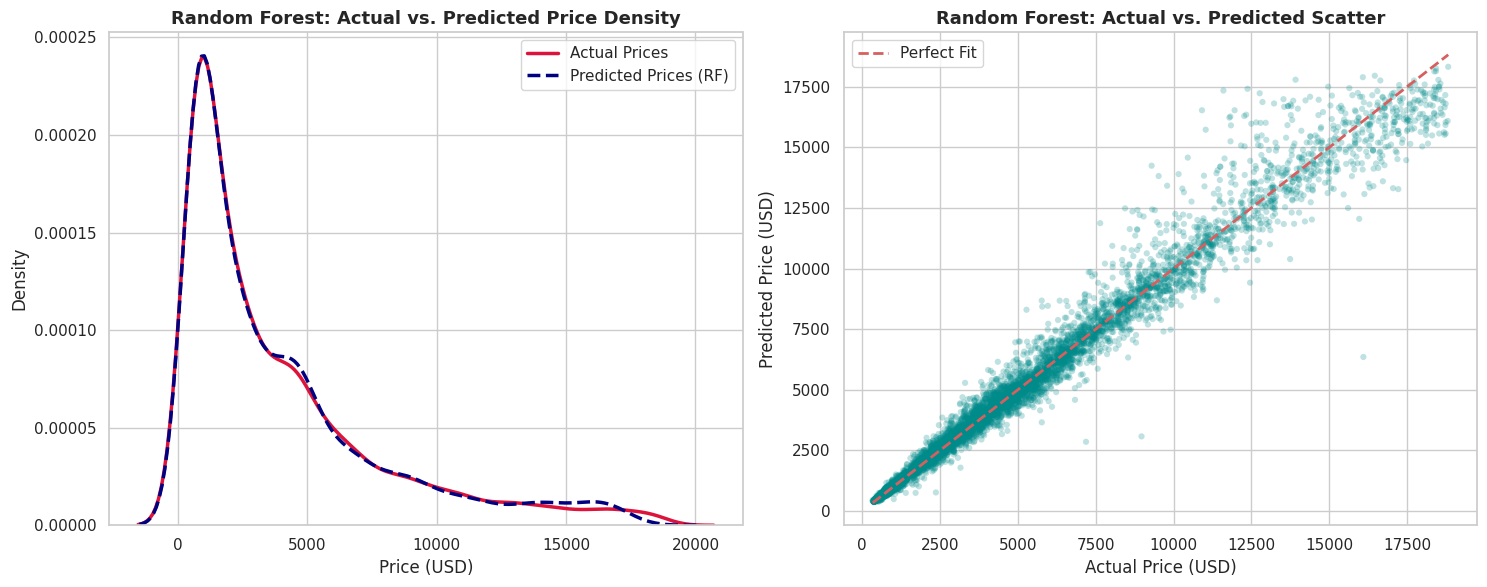

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

rf_preds = predictions['Random Forest Regressor']['test']

# Actual vs Predicted Distribution KDE
sns.kdeplot(y_test, label='Actual Prices', color='crimson', lw=2.5, ax=axes[0])
sns.kdeplot(rf_preds, label='Predicted Prices (RF)', color='navy', linestyle='--', lw=2.5, ax=axes[0])
axes[0].set_title('Random Forest: Actual vs. Predicted Price Density', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price (USD)')
axes[0].legend()

# Scatter plot: Actual vs Predicted
axes[1].scatter(y_test, rf_preds, alpha=0.25, color='darkcyan', edgecolors='none', s=20)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')
axes[1].set_title('Random Forest: Actual vs. Predicted Scatter', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Actual Price (USD)')
axes[1].set_ylabel('Predicted Price (USD)')
axes[1].legend()

plt.tight_layout()
plt.show()


## 10. Feature Importance Analysis
We extract the feature importances from the Random Forest model to understand what attributes drive diamond pricing the most.


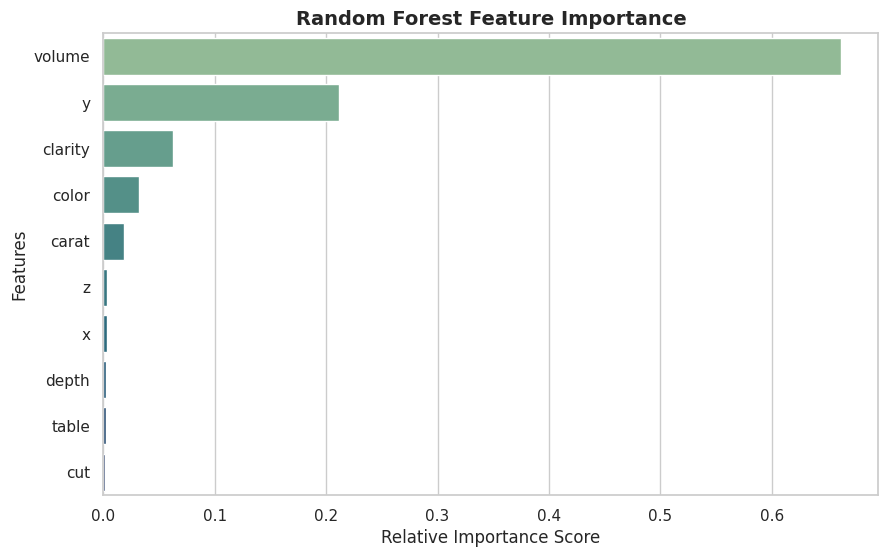

Feature Importance Scores:
volume     0.662566
y          0.211595
clarity    0.062748
color      0.031758
carat      0.018636
z          0.003421
x          0.003087
depth      0.002615
table      0.002091
cut        0.001483
dtype: float64


In [26]:
rf_model = trained_models['Random Forest Regressor']
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='crest')
plt.title('Random Forest Feature Importance', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.ylabel('Features')
plt.show()

print("Feature Importance Scores:")
print(feature_importances)


## 11. Conclusion & Key Takeaways

### Summary of Results:
1. **Model Performance Champion**:
   - **Random Forest Regressor** achieved outstanding predictive performance with **$R^2 = 0.9802$**, an **RMSE of \$556.64**, and an **MAE of \$271.66** on the unseen test set.
   - **Multiple Linear Regression** captured a strong baseline ($R^2 = 0.9113$), but failed to model the non-linear exponential price scaling with carat.
   - **Decision Tree Regressor** achieved $R^2 = 0.9625$, but suffered from extreme training overfitting ($R^2 = 1.0000$ on train data).
2. **Simpson's Paradox Resolved**:
   - The apparent counter-intuitive finding that J-color and I1-clarity diamonds command higher average prices was proven to be driven by **carat size confounding**: diamonds with lower color/clarity are only commercially viable when significantly larger.
   - Normalizing by **Price per Carat** verified that IF clarity commands a **~53% premium** over I1 clarity.
3. **Primary Price Drivers**:
   - As confirmed by the Random Forest feature importance analysis, **Carat weight** (and engineered **Volume**) alone account for over **60%** of price variance, followed by **Clarity** and **Color**.

### Future Enhancements:
- Implementation of hyperparameter optimization (GridSearchCV / Optuna) to further fine-tune the Random Forest estimator.
- Deployment of a Streamlit/FastAPI web interface allowing jewelry appraisers to input diamond dimensions and receive instant market price estimates.
